In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import matplotlib.pyplot as plt
from src.config import Config
from src.utils.seed import set_seed
from src.utils.io_helpers import save_checkpoint, save_json
from src.dataset import get_dataloaders
from src.models.vanilla_gan import VanillaGenerator, VanillaDiscriminator
from src.trainers.train_gan import train_gan
from src.evaluation.metrics import evaluate_gan_latency

set_seed(Config.SEED)
Config.ensure_dirs()
train_loader, _, _ = get_dataloaders(batch_size=Config.BATCH_SIZE, seed=Config.SEED, num_workers=0)

vanilla_gen = VanillaGenerator(noise_dim=Config.VANILLA_GAN_NOISE_DIM, output_dim=Config.INPUT_DIM)
vanilla_disc = VanillaDiscriminator(input_dim=Config.INPUT_DIM)

train_out = train_gan(
    generator=vanilla_gen,
    discriminator=vanilla_disc,
    train_loader=train_loader,
    epochs=Config.VANILLA_GAN_EPOCHS,
    lr=Config.VANILLA_GAN_LR,
    betas=Config.GAN_BETAS,
    noise_dim=Config.VANILLA_GAN_NOISE_DIM,
    device=Config.DEVICE,
    model_name="Vanilla GAN",
)

latency_ms = evaluate_gan_latency(vanilla_gen, Config.VANILLA_GAN_NOISE_DIM, Config.DEVICE)
print(f"Vanilla GAN Generator Latency (batch=64): {latency_ms} ms")

save_checkpoint(vanilla_gen, Config.CHECKPOINT_DIR / "vanilla_gan_gen.pth")
save_checkpoint(vanilla_disc, Config.CHECKPOINT_DIR / "vanilla_gan_disc.pth")
save_json(
    {
        "model": "Vanilla GAN (MLP)",
        "latent_dim": Config.VANILLA_GAN_NOISE_DIM,
        "avg_epoch_time_sec": train_out["avg_epoch_time_sec"],
        "inference_latency_ms_batch64": latency_ms,
        "history": train_out["history"],
    },
    Config.METRICS_DIR / "vanilla_gan_results.json",
)

[Vanilla GAN] Epoch 01/50 | D Loss: 1.0063 | G Loss: 1.0717 | Time: 21.70s
[Vanilla GAN] Epoch 05/50 | D Loss: 1.1275 | G Loss: 1.2574 | Time: 21.81s
[Vanilla GAN] Epoch 10/50 | D Loss: 1.2405 | G Loss: 1.0175 | Time: 26.46s
[Vanilla GAN] Epoch 15/50 | D Loss: 1.3016 | G Loss: 0.8935 | Time: 24.51s
[Vanilla GAN] Epoch 20/50 | D Loss: 1.3297 | G Loss: 0.8423 | Time: 21.92s
[Vanilla GAN] Epoch 25/50 | D Loss: 1.3435 | G Loss: 0.8115 | Time: 21.81s
[Vanilla GAN] Epoch 30/50 | D Loss: 1.3535 | G Loss: 0.7911 | Time: 20.95s
[Vanilla GAN] Epoch 35/50 | D Loss: 1.3561 | G Loss: 0.7821 | Time: 32.42s
[Vanilla GAN] Epoch 40/50 | D Loss: 1.3615 | G Loss: 0.7709 | Time: 21.99s
[Vanilla GAN] Epoch 45/50 | D Loss: 1.3658 | G Loss: 0.7588 | Time: 22.74s
[Vanilla GAN] Epoch 50/50 | D Loss: 1.3657 | G Loss: 0.7522 | Time: 31.41s
Vanilla GAN Generator Latency (batch=64): 4.3593 ms


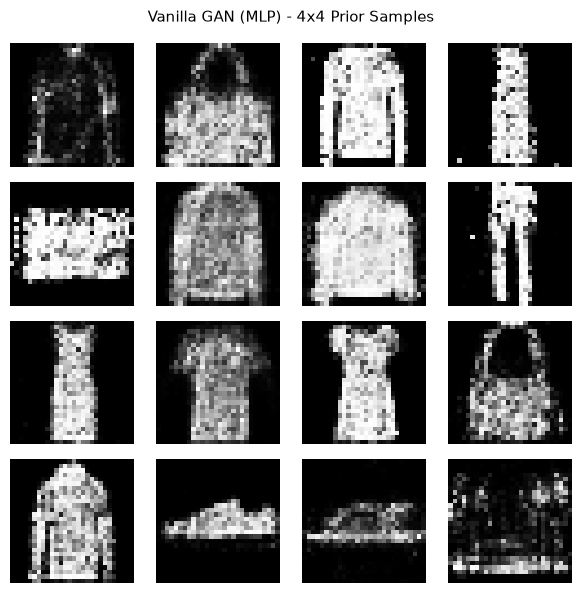

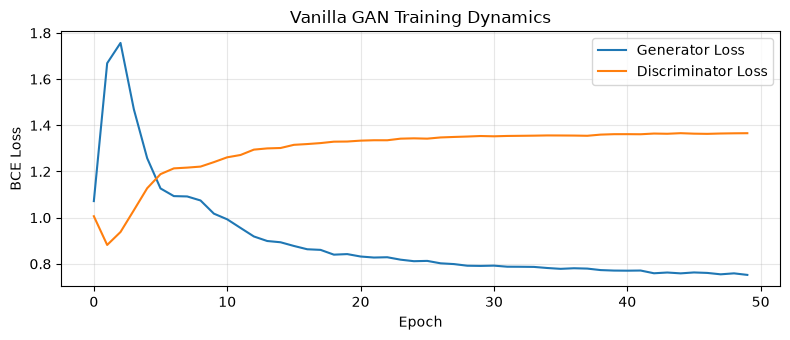

In [5]:
samples = vanilla_gen.sample(16, Config.DEVICE).cpu()

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("Vanilla GAN (MLP) - 4x4 Prior Samples", fontsize=11)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3.5))
plt.plot(train_out["history"]["g_loss"], label="Generator Loss")
plt.plot(train_out["history"]["d_loss"], label="Discriminator Loss")
plt.title("Vanilla GAN Training Dynamics")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()